<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aua26b_adaline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

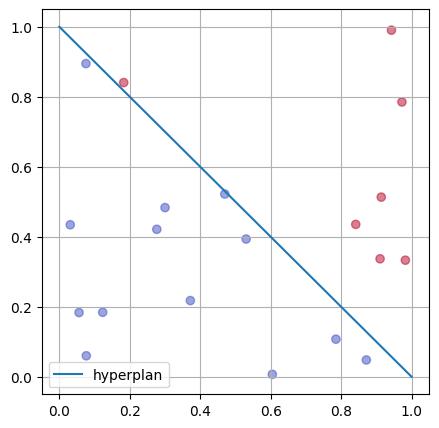

In [5]:
import numpy as np
from matplotlib import pyplot as plt

def create_dataset(n=20, coefs=[1, 1], intercept=-1):
  X = np.random.rand(n, 2)
  y = X @ coefs + intercept
  y = np.sign(y)
  return X, y

def plot_dataset(X, y):
  plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", alpha=0.5)
  plt.grid(True)

def plot_hyperplan(coefs, intercept, legend="hyperplan"):
  xs = np.array([0,1])
  ys = -(coefs[0] * xs + intercept) / coefs[1]
  plt.plot(xs, ys, label=legend)
  plt.legend()

coefs = [1, 1]
intercept = -1
X, y = create_dataset(20, coefs, intercept)

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept)
plt.show()

accuracy: 0.95
coefs: [1.64552292 1.57980319]


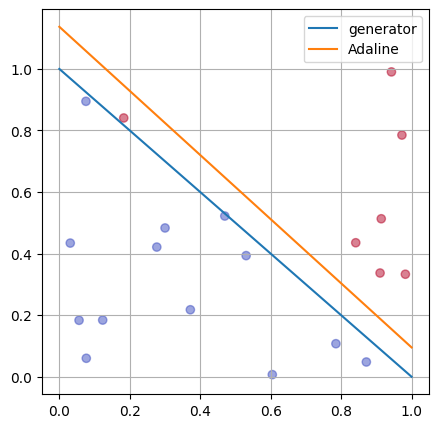

In [11]:
from numpy._core.umath import log
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

def include_bias(X):
  return np.c_[np.ones((X.shape[0],1)), X]

class Adaline(BaseEstimator, ClassifierMixin):
  def fit(self, X, y):
    Xb = include_bias(X)
    y = y.reshape(-1)
    self.w = np.linalg.pinv(Xb) @ y
    self.intercept = self.w[0]
    self.coefs = self.w[1:]
    return self

  def pre_activation(self, X):
    Xb = include_bias(X)
    logits = Xb @ self.w
    return logits

  def predict(self, X):
    logits = self.pre_activation(X)
    y_pred = np.sign(logits)
    return y_pred

clf = Adaline()
clf.fit(X, y)
y_pred = clf.predict(X)
print(f"accuracy: {accuracy_score(y, y_pred)}")
print(f"coefs: {clf.coefs}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, clf.intercept, "Adaline")
plt.show()

accuracy: 0.95
coefs: [1.64552292 1.57980319]


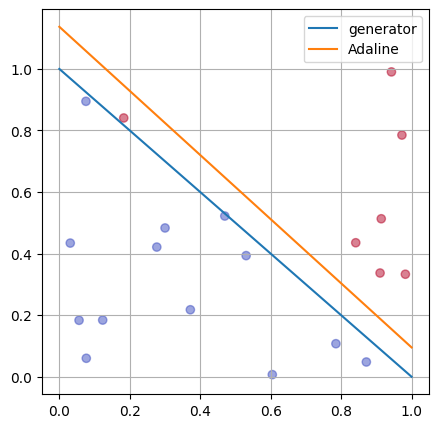

In [15]:
from numpy._core.umath import log
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

def include_bias(X):
  return np.c_[np.ones((X.shape[0],1)), X]

class Adaline(BaseEstimator, ClassifierMixin):
  def __init__(self, max_iter=1000, learning_rate=0.05):
    self.max_iter = max_iter
    self.learning_rate = learning_rate

  def fit(self, X, y):
    Xb = include_bias(X)
    y = y.reshape(-1)
    self.w = np.random.rand(Xb.shape[1])
    for _ in range(self.max_iter):
      errors = y - self.pre_activation(X)
      self.w += self.learning_rate * Xb.T @ errors
    self.intercept = self.w[0]
    self.coefs = self.w[1:]
    return self

  def pre_activation(self, X):
    Xb = include_bias(X)
    logits = Xb @ self.w
    return logits

  def predict(self, X):
    logits = self.pre_activation(X)
    y_pred = np.sign(logits)
    return y_pred

clf = Adaline()
clf.fit(X, y)
y_pred = clf.predict(X)
print(f"accuracy: {accuracy_score(y, y_pred)}")
print(f"coefs: {clf.coefs}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, clf.intercept, "Adaline")
plt.show()

accuracy: 1.0
coefs: [1.20137428 1.36396494]


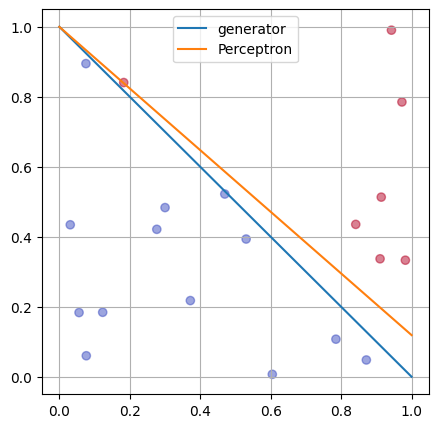

In [33]:
from numpy._core.umath import log
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

def include_bias(X):
  return np.c_[np.ones((X.shape[0],1)), X]

class Perceptron(BaseEstimator, ClassifierMixin):
  def __init__(self, max_iter=1000, learning_rate=0.05):
    self.max_iter = max_iter
    self.learning_rate = learning_rate

  def fit(self, X, y):
    Xb = include_bias(X)
    y = y.reshape(-1)
    self.w = np.random.rand(Xb.shape[1])
    for _ in range(self.max_iter):
      errors = y - self.predict(X)
      self.w += self.learning_rate * Xb.T @ errors
    self.intercept = self.w[0]
    self.coefs = self.w[1:]
    return self

  def pre_activation(self, X):
    Xb = include_bias(X)
    logits = Xb @ self.w
    return logits

  def predict(self, X):
    logits = self.pre_activation(X)
    y_pred = np.sign(logits)
    return y_pred

clf = Perceptron()
clf.fit(X, y)
y_pred = clf.predict(X)
print(f"accuracy: {accuracy_score(y, y_pred)}")
print(f"coefs: {clf.coefs}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, clf.intercept, "Perceptron")
plt.show()